In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"

RAW_DIR = (
    DATA_DIR
    / "UrbanEVDataset"
    / "20220901-20230228_station-raw"
)

CHARGE_DIR = RAW_DIR / "charge_5min"

csv_files = list(DATA_DIR.rglob("*.csv"))

print("Total CSV files:", len(csv_files))
print("Dataset directory exists:", RAW_DIR.exists())

Total CSV files: 1701
Dataset directory exists: True


## 2. Dataset Selection and Sampling

To reduce computational complexity while preserving
spatial and temporal patterns, a geographically
concentrated subset of the UrbanEV dataset is selected.

### Study Area Configuration

- Location: Futian area, Shenzhen, China
- Total stations: 100
- Center latitude: 22.54
- Center longitude: 114.05
- Maximum distance from center: 2.14 km
- Time period: December 2022 – February 2023
- Temporal resolution: 5 minutes
- Selection method: Haversine distance

This geographical selection supports regional availability
prediction, interactive map visualization, and nearby
charging station recommendations.

### 2.1. Station Information

Inspect station metadata, including geographical
coordinates and charging capacity.

In [9]:
stations = pd.read_csv(
    RAW_DIR / "station_information.csv"
)

print("Shape:", stations.shape)
print("Columns:", stations.columns.tolist())

display(stations.head())

Shape: (1682, 7)
Columns: ['station_id', 'longitude', 'latitude', 'slow_count', 'fast_count', 'charge_count', 'TAZID']


,station_id,longitude,latitude,slow_count,fast_count,charge_count,TAZID
0,1001,113.784724,22.714121,20,0,20,559
1,1002,113.785002,22.725900,22,0,22,558
2,1003,113.787971,22.735538,6,0,6,558
3,1004,113.788126,22.693449,6,5,11,596
4,1005,113.788126,22.693449,6,5,11,596


### 2.2. Charging Station Data Structure

Inspect individual station time-series files
and identify the available charging variables.

In [10]:
charge_files = sorted(CHARGE_DIR.glob("*.csv"))

print("Station CSV files:", len(charge_files))

sample = pd.read_csv(charge_files[0])

print("Sample file:", charge_files[0].name)
print("Shape:", sample.shape)
print("Columns:", sample.columns.tolist())

display(sample.head(10))

Station CSV files: 1682
Sample file: 1001.csv
Shape: (52128, 11)
Columns: ['time', 'busy', 'idle', 's_price', 'e_price', 'fast_busy', 'fast_idle', 'slow_busy', 'slow_idle', 'duration', 'volume']


,time,busy,idle,s_price,e_price,fast_busy,fast_idle,slow_busy,slow_idle,duration,volume
0,2022-09-01 00:00:00,4.0,16.0,0.47,1.2,0.0,0.0,4.0,16.0,0.000000,0.000000
1,2022-09-01 00:05:00,4.0,16.0,0.47,1.2,0.0,0.0,4.0,16.0,0.000000,0.000000
2,2022-09-01 00:10:00,4.0,16.0,0.47,1.2,0.0,0.0,4.0,16.0,0.000000,0.000000
3,2022-09-01 00:15:00,8.0,12.0,0.47,1.2,0.0,0.0,8.0,12.0,0.083333,0.583333
4,2022-09-01 00:20:00,6.0,14.0,0.47,1.2,0.0,0.0,6.0,14.0,0.083333,0.583333
5,2022-09-01 00:25:00,6.0,14.0,0.47,1.2,0.0,0.0,6.0,14.0,0.083333,0.583333
6,2022-09-01 00:30:00,6.0,14.0,0.47,1.2,0.0,0.0,6.0,14.0,0.083333,0.583333
7,2022-09-01 00:35:00,8.0,12.0,0.47,1.2,0.0,0.0,8.0,12.0,0.083333,0.583333
8,2022-09-01 00:40:00,8.0,12.0,0.47,1.2,0.0,0.0,8.0,12.0,0.083333,0.583333
9,2022-09-01 00:45:00,20.0,0.0,0.47,1.2,0.0,0.0,20.0,0.0,0.000000,0.000000


### 2.3. Geographical Distribution of Charging Stations

The geographical distribution of charging stations
is examined to identify a spatially concentrated
study area in Shenzhen.

Selecting geographically close stations supports
future map visualization and charging station
recommendations.

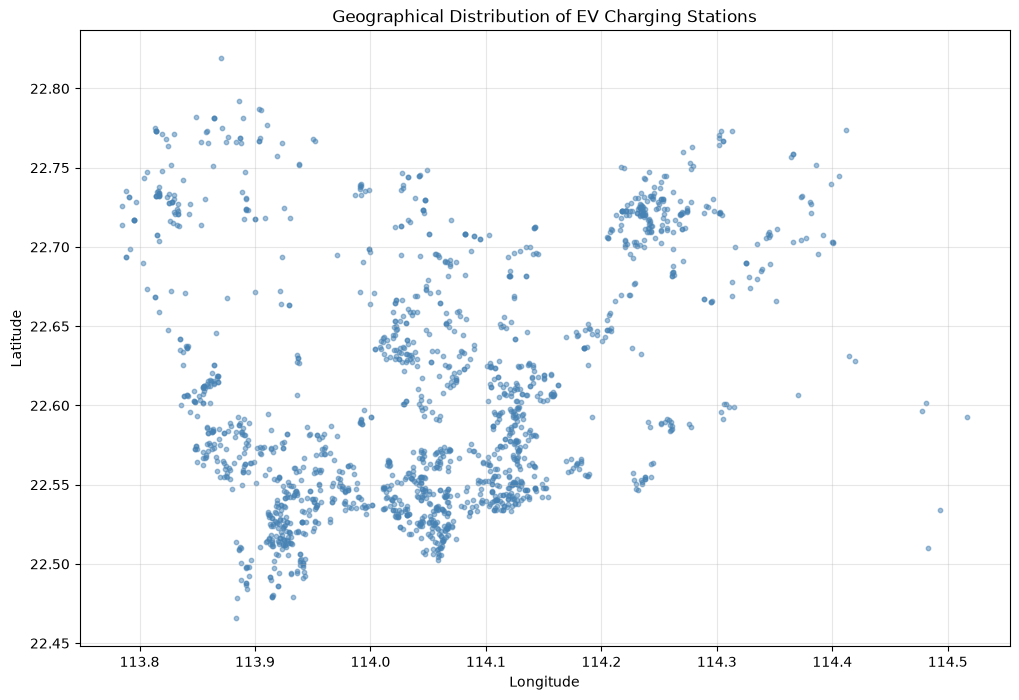

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.scatter(
    stations["longitude"],
    stations["latitude"],
    s=10,
    alpha=0.5,
    color="steelblue"
)

plt.title("Geographical Distribution of EV Charging Stations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)
plt.show()

### 2.4. Geographical Station Selection

A geographically concentrated subset of 100 charging
stations is selected around the Futian area of Shenzhen.

Stations are selected based on their geographical distance
from a fixed central point to support regional availability
prediction and interactive map visualization.

In [12]:
import numpy as np

RAW_DIR = (
    DATA_DIR
    / "UrbanEVDataset"
    / "20220901-20230228_station-raw"
)

CHARGE_DIR = RAW_DIR / "charge_5min"

CENTER_LAT = 22.54
CENTER_LON = 114.05
N_STATIONS = 100

available_ids = {
    int(file.stem)
    for file in CHARGE_DIR.glob("*.csv")
    if file.stem.isdigit()
}

eligible_stations = stations[
    stations["station_id"].isin(available_ids)
].dropna(subset=["latitude", "longitude"]).copy()

# Haversine distance in kilometers
lat = np.radians(eligible_stations["latitude"])
lon = np.radians(eligible_stations["longitude"])

center_lat = np.radians(CENTER_LAT)
center_lon = np.radians(CENTER_LON)

a = (
    np.sin((lat - center_lat) / 2)**2
    + np.cos(center_lat) * np.cos(lat)
    * np.sin((lon - center_lon) / 2)**2
)

eligible_stations["distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

selected_stations = eligible_stations.sort_values(
    ["distance_km", "station_id"]
).head(N_STATIONS).copy()

print("Selected stations:", len(selected_stations))
print("Maximum distance (km):",
      round(selected_stations["distance_km"].max(), 2))

display(selected_stations.head(10))

Selected stations: 100
Maximum distance (km): 2.14


,station_id,longitude,latitude,slow_count,fast_count,charge_count,TAZID,distance_km
846,1847,114.051136,22.538613,6,0,6,1062,0.193385
834,1835,114.048537,22.541915,11,0,11,1062,0.260611
847,1848,114.051237,22.537910,6,0,6,1062,0.264855
841,1842,114.050910,22.543973,6,0,6,1061,0.451554
814,1815,114.046011,22.543494,12,0,12,1061,0.564600
789,1790,114.044090,22.540048,5,0,5,227,0.606986
790,1791,114.044090,22.540048,5,0,5,227,0.606986
862,1863,114.054052,22.544005,26,0,26,1061,0.609504
792,1793,114.044260,22.541976,2,0,2,1062,0.629116
795,1796,114.044518,22.543329,3,0,3,1061,0.673790


### 2.5. Visualizing Selected Stations

The selected charging stations are highlighted to
verify the geographical concentration of the study area.

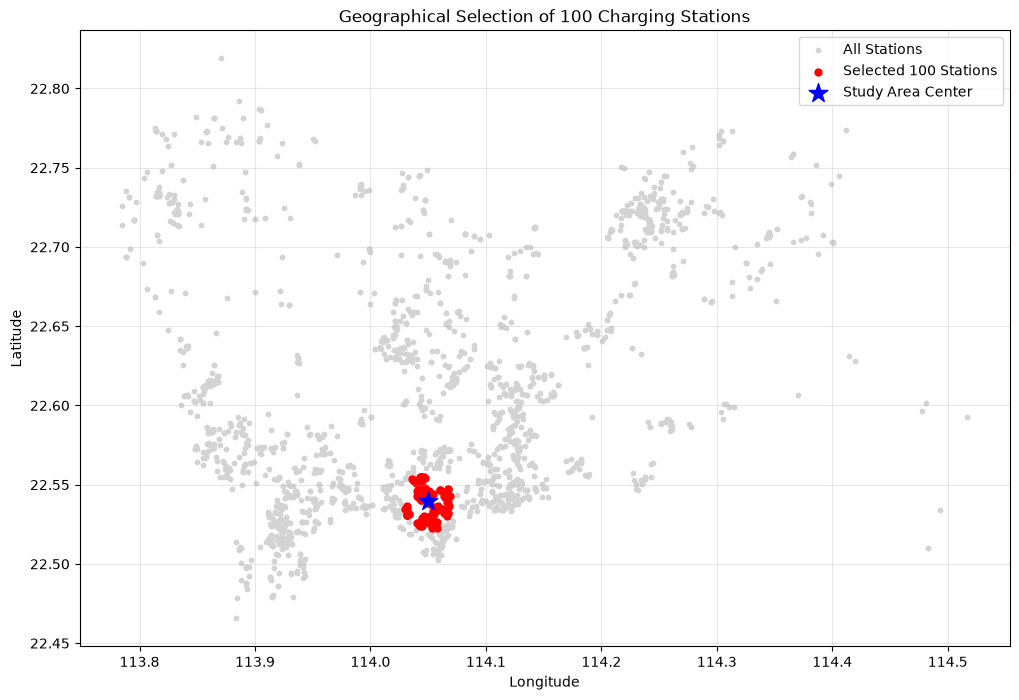

In [13]:
plt.figure(figsize=(12, 8))

plt.scatter(
    stations["longitude"],
    stations["latitude"],
    s=10,
    color="lightgray",
    label="All Stations"
)

plt.scatter(
    selected_stations["longitude"],
    selected_stations["latitude"],
    s=25,
    color="red",
    label="Selected 100 Stations"
)

plt.scatter(
    CENTER_LON,
    CENTER_LAT,
    s=200,
    color="blue",
    marker="*",
    label="Study Area Center"
)

plt.title("Geographical Selection of 100 Charging Stations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2.6. Saving Selected Stations

Export the selected station metadata to ensure
consistent dataset selection across all team members.

In [14]:
OUTPUT_DIR = ROOT / "outputs" / "tables"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

selected_stations.to_csv(
    OUTPUT_DIR / "selected_stations.csv",
    index=False
)

print("Selected stations saved successfully!")

Selected stations saved successfully!
